# Loading RQs from a file with `goldpan`, and histogramming one

*A first example for the `goldpan` / `goldsluice` note. Draft prepared with Claude Code for A. Villano, 2026-10-26.*

The RQs (reduced quantities) of a series are the numbers the collaboration's reconstruction computes for every event, stored in a ROOT file (`rqDir/eventTree` for event-level quantities and `rqDir/zip<N>` for the quantities of detector number `N`). `goldpan.adapters.rq_root.read` returns them as one table, one record per event, with the event key first (`series`, `dump`, `event`).

**The data here are made up.** No real RQ file is in the repository. `synthetic-rq/` holds two small ROOT files (24 events in all, about 9 kB each), so that you can see how the reading works on real files on disk. They were written by `python/tests/synthetic_series.py`, which is deterministic (the series name and the channel names imitate Run 76, series `07221203_2025`, but the numbers are random), and the second code cell writes them again if they are missing. To use a real file, only the path and the detector number below change. Needs `uproot` (it is in `requirements.txt`). Run with the `darkmatter_cli_env` kernel.

In [1]:
import sys
from pathlib import Path

import awkward as ak
import matplotlib.pyplot as plt
import numpy as np

from goldpan.adapters import rq_root       # `goldpan` is installed by requirements.txt (pip install -e ./python)

In [2]:
# The synthetic RQ files of this folder (rewritten from the generator if they are missing).
DATA = Path("synthetic-rq")
if not list(DATA.glob("*.root")):
    _here = Path.cwd().resolve()
    REPO = next(p for p in [_here, *_here.parents] if (p / "python" / "tests" / "synthetic_series.py").exists())
    sys.path.insert(0, str(REPO / "python" / "tests"))
    import synthetic_series as ss
    for dump in ss.all_dumps():
        ss.write_rq_root(dump, DATA)
print(sorted(p.name for p in DATA.glob("*.root")))

['07221203_2025_F0001.root', '07221203_2025_F0002.root']


In [3]:
# Read the RQs: a folder of .root files is read file after file. The detector number is never assumed: say it.
table = rq_root.read(DATA, detector=1, branches=["EventType", "PTOFamps", "Side2p*max", "Side2p*std"])

print(len(table), "events;", len(ak.fields(table)), "fields")
print(ak.fields(table))
print()
print("the first event:", ak.to_list(table[0]))

24 events; 17 fields
['series', 'dump', 'event', 'EventType', 'PTOFamps', 'Side2pAmax', 'Side2pBmax', 'Side2pCmax', 'Side2pDmax', 'Side2pEmax', 'Side2pFmax', 'Side2pAstd', 'Side2pBstd', 'Side2pCstd', 'Side2pDstd', 'Side2pEstd', 'Side2pFstd']

the first event: {'series': '07221203_2025', 'dump': 'F0001', 'event': 10000, 'EventType': 1, 'PTOFamps': 6.076064646464648e-05, 'Side2pAmax': 12.640232323232322, 'Side2pBmax': 7.801030303030301, 'Side2pCmax': 13.088737373737377, 'Side2pDmax': 11.330232323232323, 'Side2pEmax': 5.829717171717175, 'Side2pFmax': 10.070696969696975, 'Side2pAstd': 2.981841620723076e-08, 'Side2pBstd': 2.983708442490452e-08, 'Side2pCstd': 3.033019825909613e-08, 'Side2pDstd': 3.0064687256898536e-08, 'Side2pEstd': 2.957136220582148e-08, 'Side2pFstd': 3.0318496053374345e-08}


Side2pCmax, the pulse height of channel Side2pC above its pretrigger baseline (microamps), events per bin:
       0.1 to      1.3   13
       1.3 to      2.5    0
       2.5 to      3.7    0
       3.7 to      4.9    0
       4.9 to      6.1    1
       6.1 to      7.3    2
       7.3 to      8.5    0
       8.5 to      9.7    3
       9.7 to     10.9    1
      10.9 to     12.1    1
      12.1 to     13.3    2
      13.3 to     14.6    1


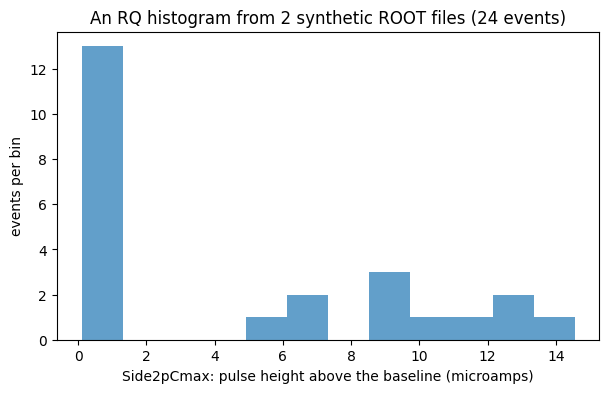

In [4]:
# An RQ histogram: the distribution of one quantity over the events.
def rq_histogram(table, name, bins):
    """Counts and bin edges of the RQ `name` of `table` (NaN, where a detector was not read out, is left out)."""
    values = ak.to_numpy(table[name]).astype(float)
    return np.histogram(values[np.isfinite(values)], bins=bins)


counts, edges = rq_histogram(table, "Side2pCmax", bins=12)
print("Side2pCmax, the pulse height of channel Side2pC above its pretrigger baseline (microamps), events per bin:")
for lo, hi, n in zip(edges[:-1], edges[1:], counts):
    print(f"  {lo:8.1f} to {hi:8.1f}  {n:3d}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.stairs(counts, edges, fill=True, alpha=0.7)
ax.set_xlabel("Side2pCmax: pulse height above the baseline (microamps)")
ax.set_ylabel("events per bin")
ax.set_title(f"An RQ histogram from {len(list(DATA.glob('*.root')))} synthetic ROOT files ({len(table)} events)")
plt.show()

**What this shows, and what is next.** `rq_root.read` gives a table, and a histogram of an RQ is a `numpy` histogram of one of its columns. Two things this draft does not do yet: it does not join the RQs to the traces of the same events (`goldpan.adapters.rq.attach(events, table)` does that, matching on `series`, `dump` and `event`), and it does not apply cuts (`goldpan.rq_cuts`). The names of the real RQs of a series, and which detector number to ask for, come from the reconstruction of that series.